In [38]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os
#%pip install missingno
import missingno as msno
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
#%pip install plotly
import plotly.graph_objects as go
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, Normalizer, Binarizer, RobustScaler, label_binarize
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, PowerTransformer
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.tree import DecisionTreeClassifier, export_text, DecisionTreeRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score

  Using cached plotly-6.6.0-py3-none-any.whl.metadata (8.5 kB)
Using cached plotly-6.6.0-py3-none-any.whl (9.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.0.1
[notice] To update, run: C:\Users\Sebitas\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


# 1) Preprocesamiento

In [11]:
warnings.filterwarnings('ignore')
df = pd.read_csv("BBDD_ML_TAREA.csv")
df.head() #por comodidad visual cambiaré el nombre de las variables. 

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V12,V13,V14,V15,V16,V17,V18,V19,V20,Y
0,43,121,415.0,1118,0,0,0,86.1,100,14.64,...,113,22.08,148.0,79.0,6.66,9.1,9,2.46,2,0
1,7,170,510.0,3326,0,0,0,184.1,106,31.30,...,70,17.42,224.3,133.0,10.09,9.8,3,2.65,2,0
2,31,96,510.0,2146,0,0,0,150.0,122,25.50,...,116,18.57,212.4,89.0,9.56,9.8,1,2.65,3,0
3,17,90,415.0,387,0,0,0,193.7,83,32.93,...,79,13.11,299.0,60.0,13.46,12.7,3,3.43,1,0
4,7,61,415.0,313,0,0,0,140.6,89,23.90,...,128,14.69,212.4,97.0,9.56,13.6,4,3.67,1,0


In [14]:
diccionario = {
    'V1': 'estado',
    'V2': 'duracion_cuenta',
    'V3': 'codigo_area',
    'V4': 'telefono',
    'V5': 'plan_internacional',
    'V6': 'plan_buzon',
    'V7': 'msgs_buzon',
    'V8': 'min_diurnas',
    'V9': 'num_diurnas',
    'V10': 'coste_diurnas',
    'V11': 'min_vespertinas',
    'V12': 'num_vespertinas',
    'V13': 'coste_vespertinas',
    'V14': 'min_nocturnas',
    'V15': 'num_nocturnas',
    'V16': 'coste_nocturnas',
    'V17': 'min_internacionales',
    'V18': 'num_internacionales',
    'V19': 'coste_internacionales',
    'V20': 'llamadas_atencion',
    'Y': 'abandono'
}

df = df.rename(columns=diccionario)
df.head()

,estado,duracion_cuenta,codigo_area,telefono,plan_internacional,plan_buzon,msgs_buzon,min_diurnas,num_diurnas,coste_diurnas,...,num_vespertinas,coste_vespertinas,min_nocturnas,num_nocturnas,coste_nocturnas,min_internacionales,num_internacionales,coste_internacionales,llamadas_atencion,abandono
0,43,121,415.0,1118,0,0,0,86.1,100,14.64,...,113,22.08,148.0,79.0,6.66,9.1,9,2.46,2,0
1,7,170,510.0,3326,0,0,0,184.1,106,31.30,...,70,17.42,224.3,133.0,10.09,9.8,3,2.65,2,0
2,31,96,510.0,2146,0,0,0,150.0,122,25.50,...,116,18.57,212.4,89.0,9.56,9.8,1,2.65,3,0
3,17,90,415.0,387,0,0,0,193.7,83,32.93,...,79,13.11,299.0,60.0,13.46,12.7,3,3.43,1,0
4,7,61,415.0,313,0,0,0,140.6,89,23.90,...,128,14.69,212.4,97.0,9.56,13.6,4,3.67,1,0


In [29]:
df.info() #veo variables con nulos. No hay tipo objects.
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 9200 entries, 0 to 9199
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   estado                 9200 non-null   category
 1   duracion_cuenta        9200 non-null   int64   
 2   codigo_area            9125 non-null   float64 
 3   telefono               9200 non-null   int64   
 4   plan_internacional     9200 non-null   int64   
 5   plan_buzon             9200 non-null   int64   
 6   msgs_buzon             9200 non-null   int64   
 7   min_diurnas            9200 non-null   float64 
 8   num_diurnas            9200 non-null   int64   
 9   coste_diurnas          9174 non-null   float64 
 10  min_vespertinas        9200 non-null   float64 
 11  num_vespertinas        9200 non-null   int64   
 12  coste_vespertinas      9200 non-null   float64 
 13  min_nocturnas          9128 non-null   float64 
 14  num_nocturnas          9140 non-null   float64 
 15

## Revisión/transformación categorías de variables

In [25]:
print(df["estado"].describe) #Estado/región están en código, se tienen que transformar a categórica para no inducir ruido. 
df['estado'] = df['estado'].astype('category', errors= "raise")

<bound method NDFrame.describe of 0       43
1        7
2       31
3       17
4        7
        ..
9195    48
9196    44
9197    47
9198    26
9199    22
Name: estado, Length: 9200, dtype: int64>


In [26]:
print(df["estado"].describe) #No tengo info de qué significa cada código, pero mantengo para no perder info relevante (región del cliente).

<bound method NDFrame.describe of 0       43
1        7
2       31
3       17
4        7
        ..
9195    48
9196    44
9197    47
9198    26
9199    22
Name: estado, Length: 9200, dtype: category
Categories (51, int64): [0, 1, 2, 3, ..., 47, 48, 49, 50]>


## Diagnóstico de NAs

In [114]:
print(df.isnull().sum())

estado                    0
duracion_cuenta           0
codigo_area              75
telefono                  0
plan_internacional        0
plan_buzon                0
msgs_buzon                0
min_diurnas               0
num_diurnas               0
coste_diurnas            26
min_vespertinas           0
num_vespertinas           0
coste_vespertinas         0
min_nocturnas            72
num_nocturnas            60
coste_nocturnas           0
min_internacionales       0
num_internacionales       0
coste_internacionales    44
llamadas_atencion         0
abandono                  0
dtype: int64


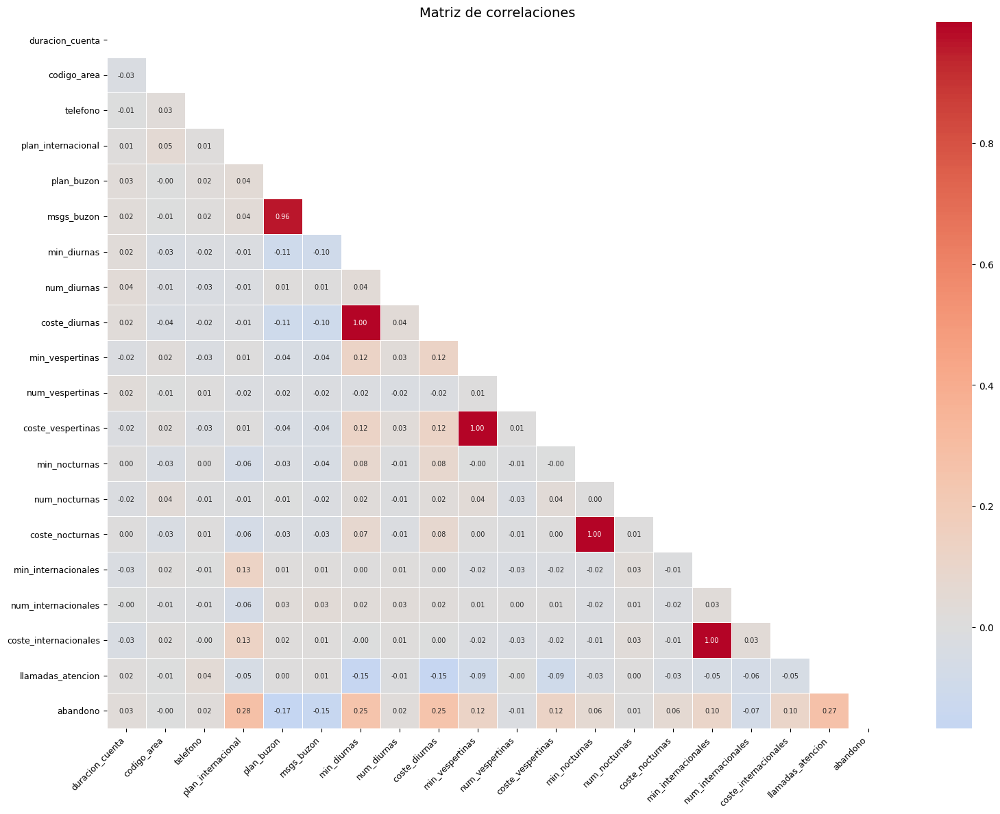

In [112]:
corr = df.select_dtypes(include=['float64','int64']).corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(16, 12))
sns.heatmap(corr, 
            mask=mask,
            annot=True, 
            fmt='.2f',
            cmap='coolwarm', 
            center=0,
            annot_kws={'size': 7},
            linewidths=0.5)
plt.title('Matriz de correlaciones', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

In [31]:
ratio = df['coste_diurnas'] / df['min_diurnas']
print(ratio.dropna().describe())
print(ratio.dropna().unique()) #veo un ratio por llamada casi constante de 0,17€ por minuto. Puedo sacar los NAs asumiendo tarifa constante.

count    9162.000000
mean        0.170003
std         0.000024
min         0.169231
25%         0.169989
50%         0.170004
75%         0.170015
max         0.170513
dtype: float64
[0.17003484 0.1700163  0.17       ... 0.17001153 0.17000883 0.17000914]


In [48]:
datos = df.copy() # Creo la copia del dataset original.
datos = datos.drop(columns=["codigo_area", "telefono"])

# Calcular la tarifa constante
tarifa_diurna = (datos['coste_diurnas'] / datos['min_diurnas']).dropna().mean()

# Imputar NAs usando la tarifa constante
datos['coste_diurnas'] = datos['coste_diurnas'].fillna(
    datos['min_diurnas'] * tarifa_diurna
)

In [49]:
print(datos.isnull().sum())

estado                    0
duracion_cuenta           0
plan_internacional        0
plan_buzon                0
msgs_buzon                0
min_diurnas               0
num_diurnas               0
coste_diurnas             0
min_vespertinas           0
num_vespertinas           0
coste_vespertinas         0
min_nocturnas            72
num_nocturnas            60
coste_nocturnas           0
min_internacionales       0
num_internacionales       0
coste_internacionales    44
llamadas_atencion         0
abandono                  0
dtype: int64


In [115]:
# Solo variables con NAs
nas = datos.isnull().sum()
nas_presentes = nas[nas > 0].reset_index()
nas_presentes.columns = ['Variable', 'Valores ausentes']
nas_presentes['% sobre total'] = (nas_presentes['Valores ausentes'] / len(datos) * 100).round(2)

print(nas_presentes.to_string(index=False))

             Variable  Valores ausentes  % sobre total
        min_nocturnas                72           0.78
        num_nocturnas                60           0.65
coste_internacionales                44           0.48


['min_nocturnas', 'num_nocturnas', 'coste_internacionales']


<Axes: >

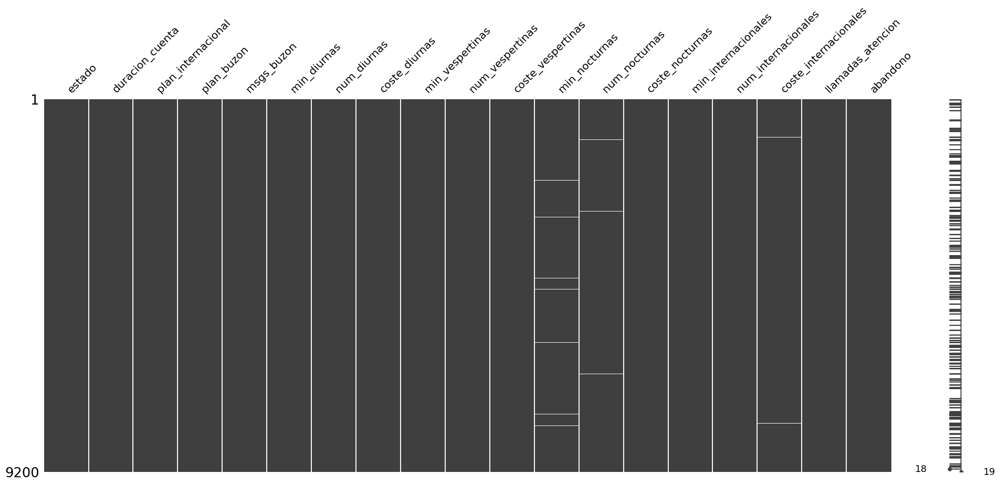

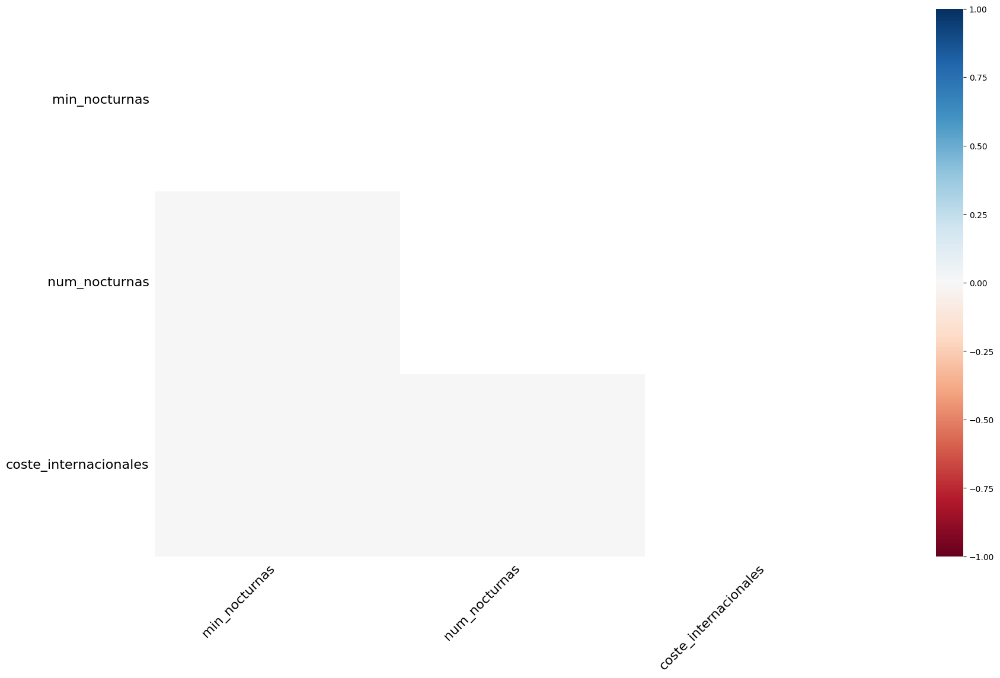

In [50]:
# Correlación de NAs:
msno.matrix(datos)
cols_con_na = datos.columns[datos.isnull().any()].tolist()
print(cols_con_na)
msno.heatmap(datos[cols_con_na])
# no veo correlaciones entre valores perdidos de las variables.

In [52]:

for col in ['min_nocturnas', 'num_nocturnas', 'coste_internacionales']:
    datos[f'na_{col}'] = datos[col].isna().astype(int)
    print(f"\n--- {col} ---")
    print(datos.groupby(f'na_{col}')[['abandono']].mean())
    datos.drop(f'na_{col}', axis=1, inplace=True) #Veo que tengo NAs no intencionados pero en coste_internacionales si parece haber una no respuesta intencionada!!.


--- min_nocturnas ---
                  abandono
na_min_nocturnas          
0                 0.499671
1                 0.541667

--- num_nocturnas ---
                  abandono
na_num_nocturnas          
0                 0.500547
1                 0.416667

--- coste_internacionales ---
                          abandono
na_coste_internacionales          
0                         0.499454
1                         0.613636


In [117]:
resultados_nas = []

for col in ['min_nocturnas', 'num_nocturnas', 'coste_internacionales']:
    datos[f'na_{col}'] = datos[col].isna().astype(int)
    tasas = datos.groupby(f'na_{col}')[['abandono']].mean()
    resultados_nas.append({
        'Variable': col,
        'Tasa abandono (sin NA)': tasas.loc[0, 'abandono'].round(4),
        'Tasa abandono (con NA)': tasas.loc[1, 'abandono'].round(4),
        'Diferencia': (tasas.loc[1, 'abandono'] - tasas.loc[0, 'abandono']).round(4)
    })
    datos.drop(f'na_{col}', axis=1, inplace=True)

resumen_nas = pd.DataFrame(resultados_nas)
print(resumen_nas.to_string(index=False))

             Variable  Tasa abandono (sin NA)  Tasa abandono (con NA)  Diferencia
        min_nocturnas                  0.4997                  0.5417      0.0420
        num_nocturnas                  0.5005                  0.4167     -0.0839
coste_internacionales                  0.4995                  0.6136      0.1142


## Diagnóstico Outliers: Necesario antes de imputar o tratar los NAs

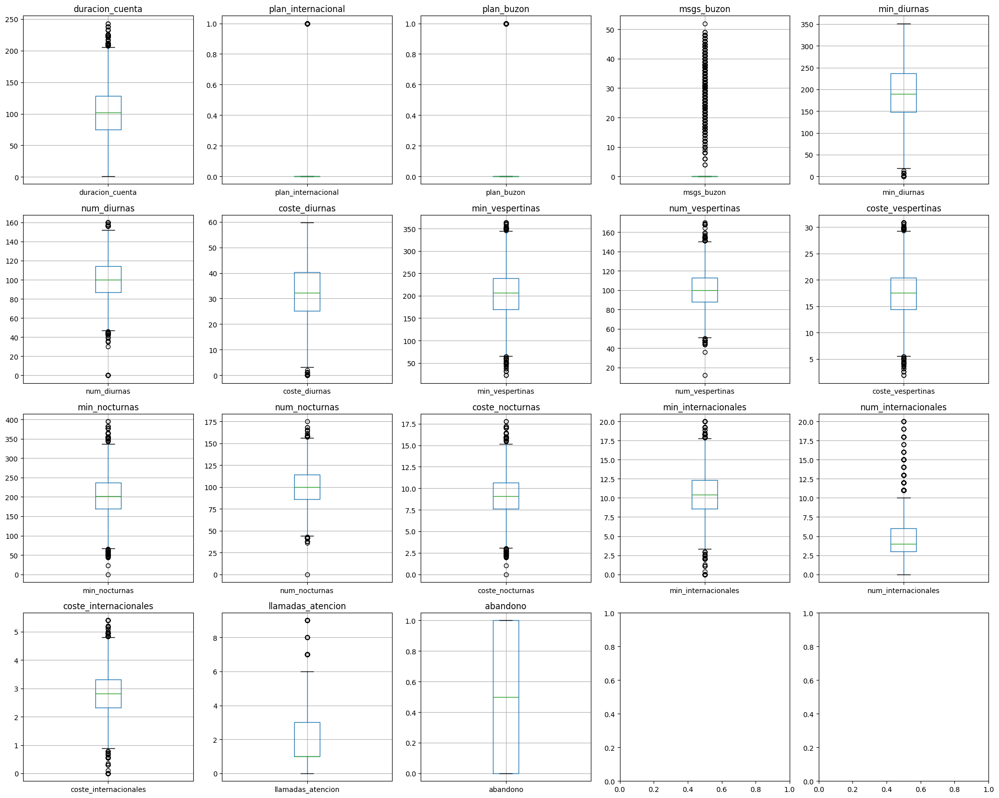

In [56]:
variables_numericas = datos.select_dtypes(include=['float64', 'int64']).columns.tolist()

fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(variables_numericas):
    datos.boxplot(column=col, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()
plt.close()

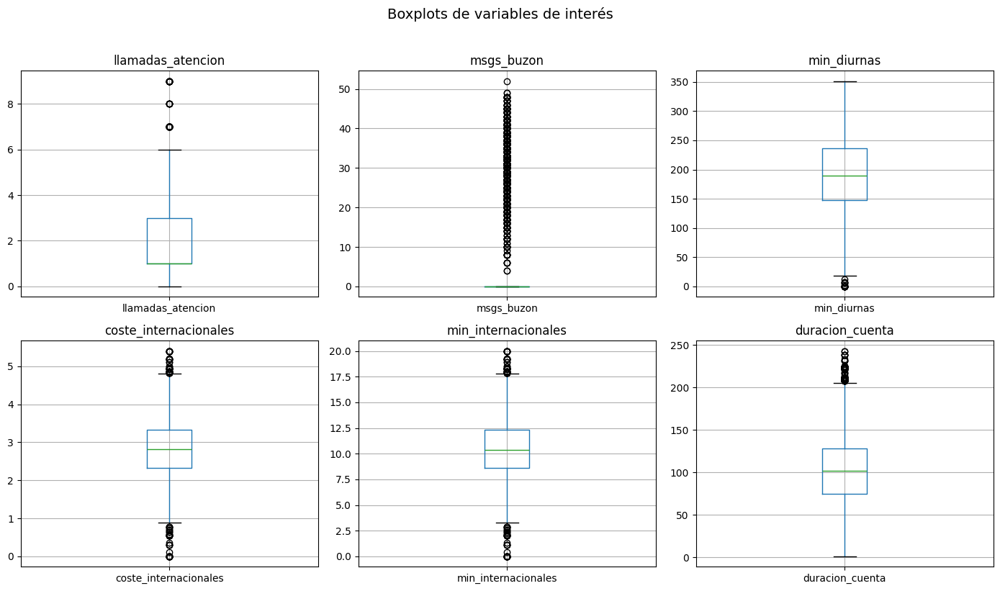

In [118]:
vars_interes = ['llamadas_atencion', 'msgs_buzon', 
                'min_diurnas', 'coste_internacionales',
                'min_internacionales', 'duracion_cuenta']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(vars_interes):
    datos.boxplot(column=col, ax=axes[i])
    axes[i].set_title(col)

plt.suptitle('Boxplots de variables de interés', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

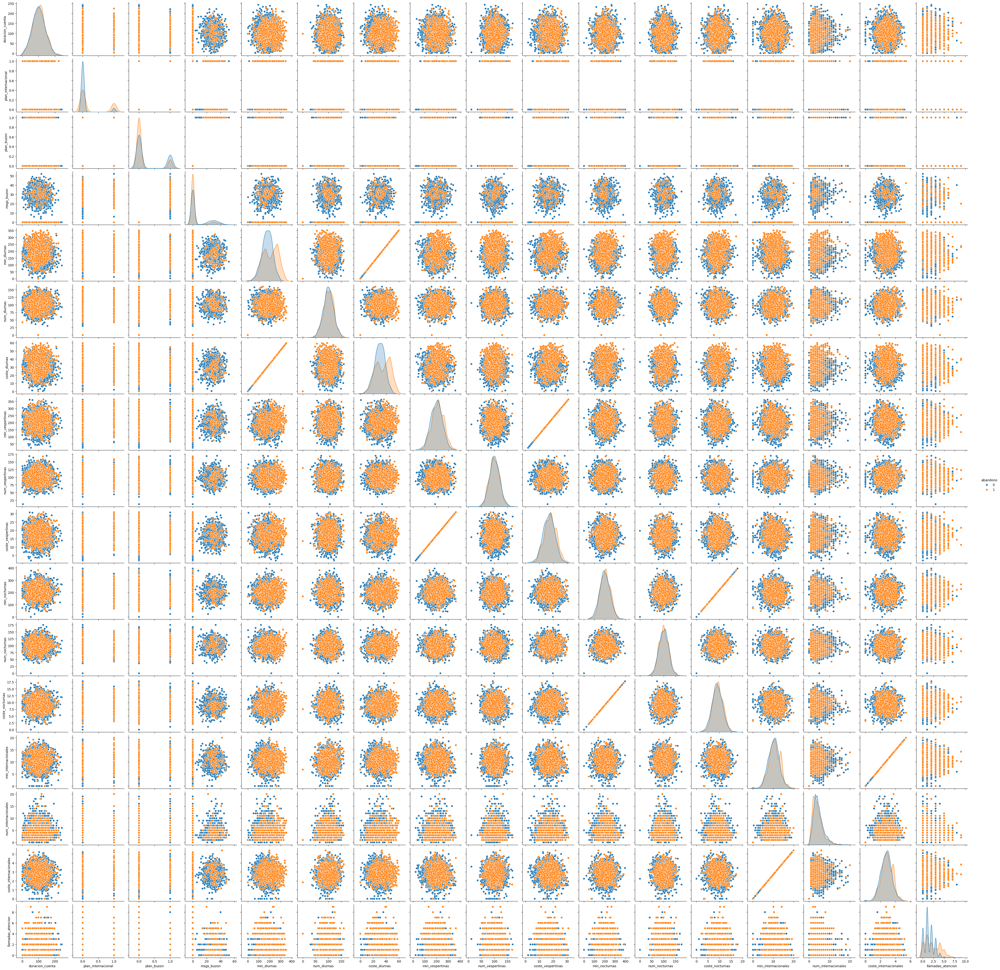

In [58]:
sns.pairplot(datos, hue='abandono')
plt.show()
plt.close()

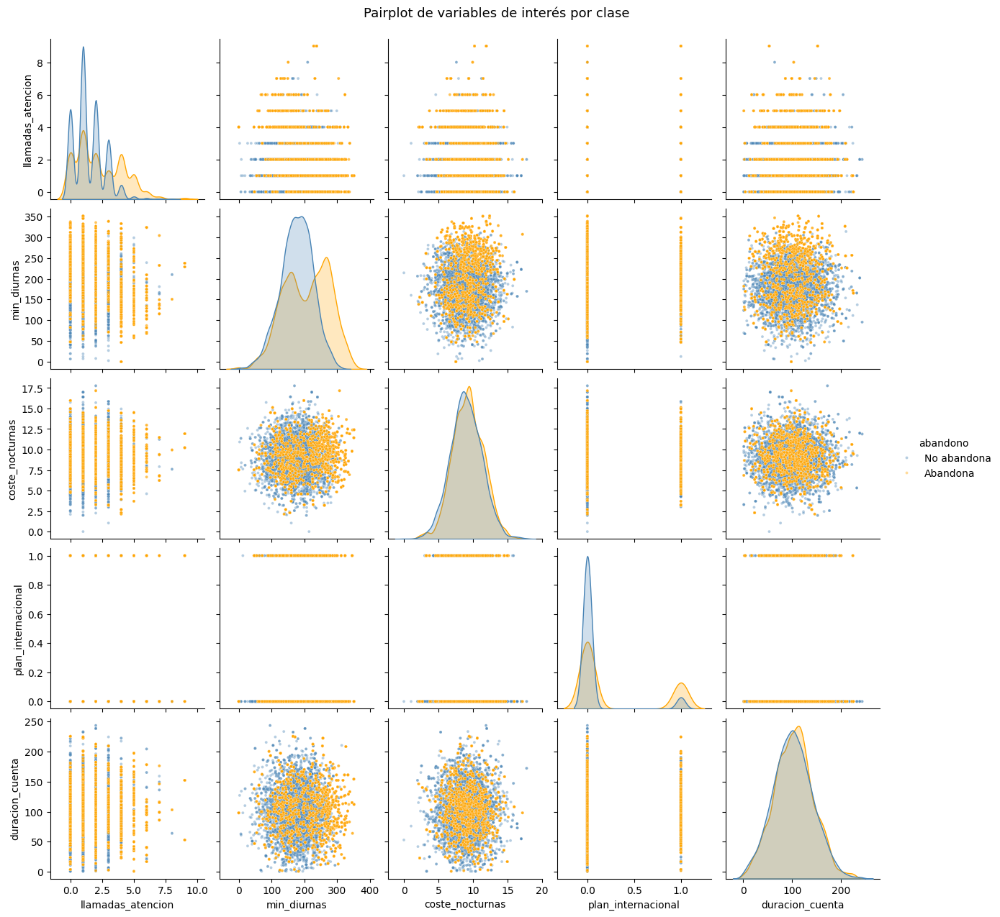

In [121]:
vars_pairplot = ['llamadas_atencion', 'min_diurnas', 
                 'coste_nocturnas', 'plan_internacional',
                 'duracion_cuenta', 'abandono']

df_plot = datos[vars_pairplot].copy()
df_plot['abandono'] = df_plot['abandono'].map({0: 'No abandona', 1: 'Abandona'})

sns.pairplot(df_plot, 
             hue='abandono',
             plot_kws={'alpha': 0.4, 's': 8},
             diag_kind='kde',
             palette={'No abandona': 'steelblue', 'Abandona': 'orange'})
plt.suptitle('Pairplot de variables de interés por clase', 
             y=1.02, fontsize=13)
plt.show()

In [120]:
print(datos['abandono'].value_counts())
print(datos['abandono'].unique())

abandono
0    4600
1    4600
Name: count, dtype: int64
[0 1]


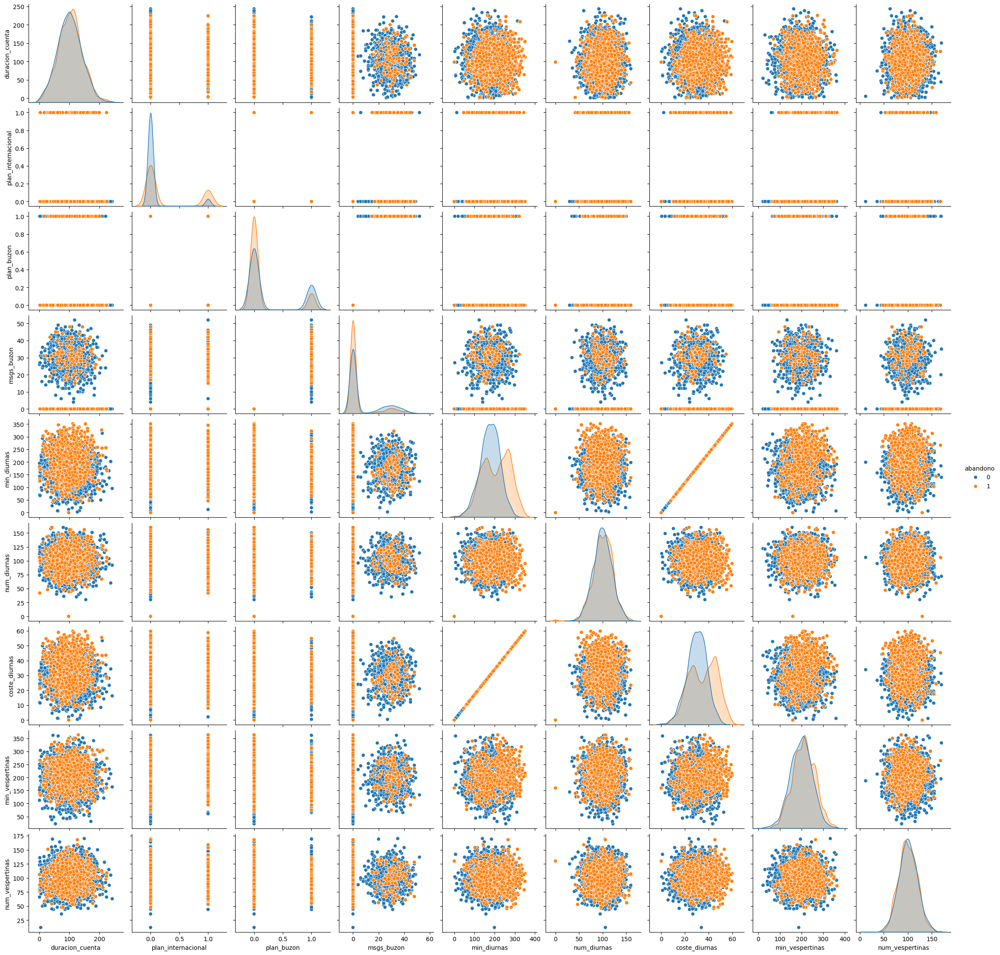

In [70]:
subset1 = datos.iloc[:, :10].copy()
subset1['abandono'] = datos['abandono']

sns.pairplot(subset1, hue='abandono')

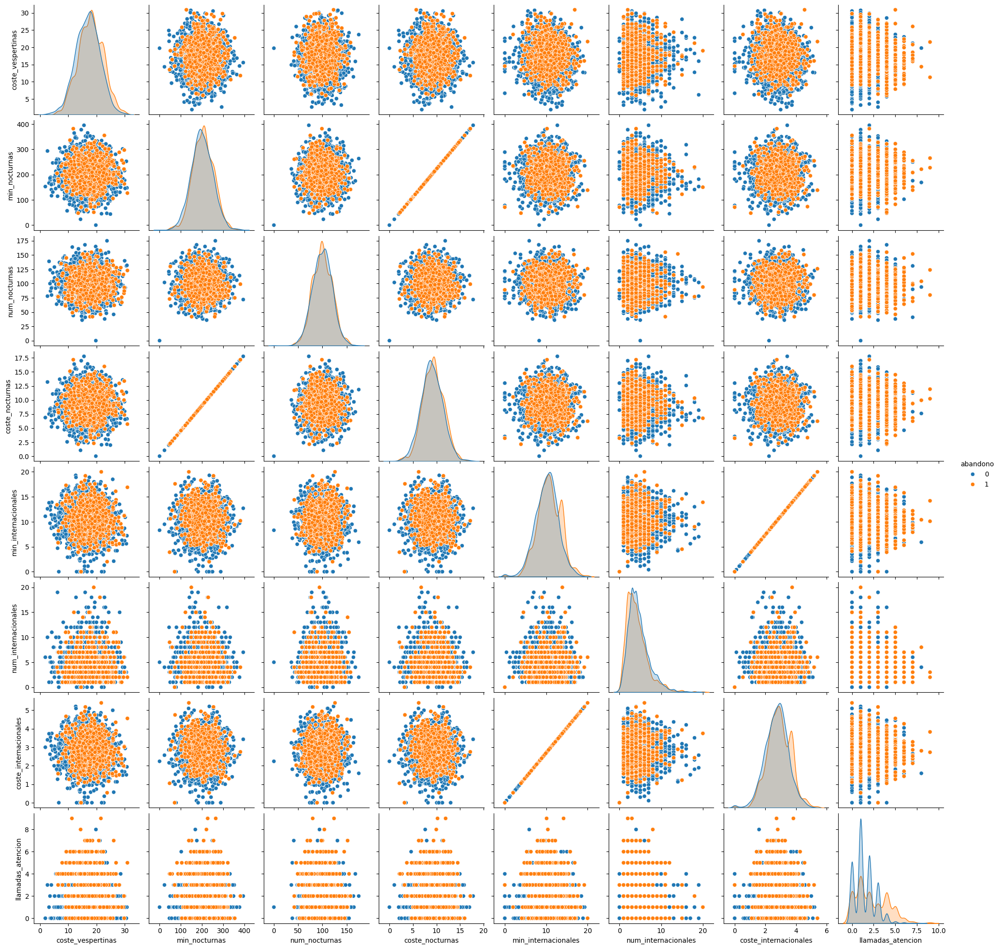

In [71]:
subset2 = datos.iloc[:, 10:20].copy()
subset2['abandono'] = datos['abandono']

sns.pairplot(subset2, hue='abandono')

## Tratamiento de NAs / estandarización:

In [59]:
print(datos['estado'].nunique())
print(datos['abandono'].value_counts(normalize=True))

51
abandono
0    0.5
1    0.5
Name: proportion, dtype: float64


In [86]:
seed= 42
X = datos.drop(columns=['abandono'])
y = datos['abandono']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
from sklearn.preprocessing import OrdinalEncoder
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import TargetEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import IterativeImputer, SimpleImputer

cols_categoricas = ['estado']
cols_binarias = ['plan_internacional', 'plan_buzon']
cols_numericas_con_na_mcar = ['min_nocturnas', 'num_nocturnas']
cols_numericas_con_na_mar = ['coste_internacionales']
cols_numericas_sin_na = [col for col in X.select_dtypes(
    include=['float64','int64']).columns
    if col not in cols_binarias + 
    cols_numericas_con_na_mcar + 
    cols_numericas_con_na_mar]

preprocessor = ColumnTransformer(transformers=[
    ('target_enc', TargetEncoder(smooth='auto'), cols_categoricas),
    ('binarias', 'passthrough', cols_binarias),
    ('num_mcar', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ]), cols_numericas_con_na_mcar),
    ('num_mar', Pipeline([
        ('scaler', RobustScaler()),
        ('imputer', IterativeImputer(random_state=seed, max_iter=10))
    ]), cols_numericas_con_na_mar),
    ('num', RobustScaler(), cols_numericas_sin_na)
])

X_train = preprocessor.fit_transform(X_train, y_train)
X_test = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
feature_names = [f.replace('target_enc__', '')
                  .replace('binarias__', '')
                  .replace('num_mcar__', '')
                  .replace('num_mar__', '')
                  .replace('num__', '') 
                  for f in feature_names]

X_train = pd.DataFrame(X_train, columns=feature_names)
X_test = pd.DataFrame(X_test, columns=feature_names)
print(X_train.columns.tolist())

['estado', 'plan_internacional', 'plan_buzon', 'min_nocturnas', 'num_nocturnas', 'coste_internacionales', 'duracion_cuenta', 'msgs_buzon', 'min_diurnas', 'num_diurnas', 'coste_diurnas', 'min_vespertinas', 'num_vespertinas', 'coste_vespertinas', 'coste_nocturnas', 'min_internacionales', 'num_internacionales', 'llamadas_atencion']


In [88]:
X_train["estado"]

0       0.251861
1       0.365878
2       0.533089
3       0.416067
4       0.303635
          ...   
7355    0.306987
7356    0.531610
7357    0.523669
7358    0.565800
7359    0.432134
Name: estado, Length: 7360, dtype: float64

In [87]:
# 1. Verificar dimensiones
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

# 2. Verificar que no quedan NAs
print("\nNAs en X_train:", pd.DataFrame(X_train).isnull().sum().sum())
print("NAs en X_test:", pd.DataFrame(X_test).isnull().sum().sum())

# 3. Verificar proporciones de y tras el split
print("\nProporción y_train:")
print(pd.Series(y_train).value_counts(normalize=True))
print("\nProporción y_test:")
print(pd.Series(y_test).value_counts(normalize=True))

X_train shape: (7360, 18)
X_test shape: (1840, 18)

NAs en X_train: 0
NAs en X_test: 0

Proporción y_train:
abandono
1    0.5
0    0.5
Name: proportion, dtype: float64

Proporción y_test:
abandono
1    0.5
0    0.5
Name: proportion, dtype: float64


# 2) Regresión logística y red neuronal: RFE

In [90]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

rfe = RFE(
    estimator=LogisticRegression(random_state=seed, max_iter=1000),
    n_features_to_select=5
)

rfe.fit(X_train, y_train)

# Ver qué variables seleccionó
variables_seleccionadas = X_train.columns[rfe.support_].tolist()
print("Variables seleccionadas por RFE:", variables_seleccionadas)

# Ver el ranking de todas las variables
ranking = pd.Series(rfe.ranking_, index=X_train.columns).sort_values()
print("\nRanking completo:")
print(ranking)
# Filtrar X_train y X_test con las 5 variables
X_train= X_train[variables_seleccionadas]
X_test = X_test[variables_seleccionadas]


Variables seleccionadas por RFE: ['estado', 'plan_internacional', 'min_diurnas', 'coste_nocturnas', 'llamadas_atencion']

Ranking completo:
estado                    1
plan_internacional        1
coste_nocturnas           1
min_diurnas               1
llamadas_atencion         1
min_nocturnas             2
plan_buzon                3
coste_diurnas             4
min_vespertinas           5
min_internacionales       6
coste_vespertinas         7
num_internacionales       8
num_diurnas               9
num_nocturnas            10
duracion_cuenta          11
coste_internacionales    12
msgs_buzon               13
num_vespertinas          14
dtype: int64


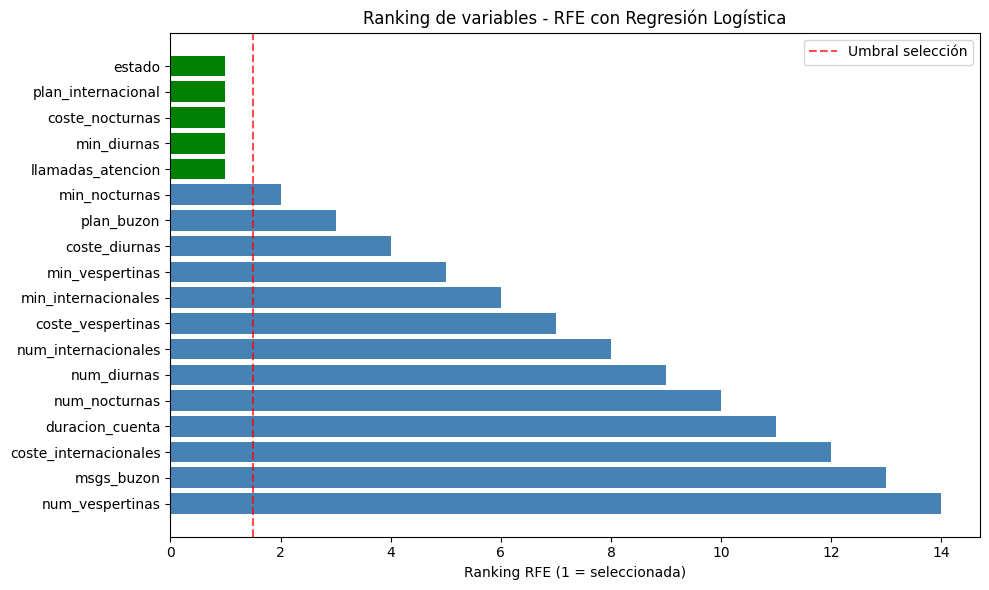

In [127]:
# rfe recuerda las variables originales con las que fue entrenado
ranking_rfe = pd.Series(
    rfe.ranking_, 
    index=rfe.feature_names_in_  # nombres originales guardados en el objeto rfe
).sort_values()

colores = ['green' if r == 1 else 'steelblue' for r in ranking_rfe.values]

plt.figure(figsize=(10, 6))
plt.barh(ranking_rfe.index, ranking_rfe.values, color=colores)
plt.axvline(x=1.5, color='red', linestyle='--', 
            alpha=0.7, label='Umbral selección')
plt.xlabel('Ranking RFE (1 = seleccionada)')
plt.title('Ranking de variables - RFE con Regresión Logística')
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [91]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score
import numpy as np

params = {
    'hidden_layer_sizes': [(5,), (10,), (20,), (30,)],
    'activation': ['tanh', 'relu', 'logistic'],
    'solver': ['adam', 'sgd'],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate': ['constant', 'adaptive'],
    'learning_rate_init': [0.001, 0.01],
    'max_iter': [500, 1000]
}

scoring = ['accuracy', 'recall_macro', 'f1_macro', 'precision_macro']

modelo_rfe = RandomizedSearchCV(
    estimator=MLPClassifier(random_state=seed),
    param_distributions=params,
    n_iter=50,
    cv=5,
    scoring=scoring,
    refit='accuracy',
    random_state=seed,
    n_jobs=-1,
    verbose=1
)

modelo_rfe.fit(X_train, y_train)

print("Mejores parámetros:", modelo_rfe.best_params_)
print("Mejor Accuracy CV:", modelo_rfe.best_score_.round(4))

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Mejores parámetros: {'solver': 'adam', 'max_iter': 1000, 'learning_rate_init': 0.01, 'learning_rate': 'constant', 'hidden_layer_sizes': (30,), 'alpha': 0.001, 'activation': 'tanh'}
Mejor Accuracy CV: 0.8463


Threshold óptimo: 0.59
Accuracy máxima: 0.8283


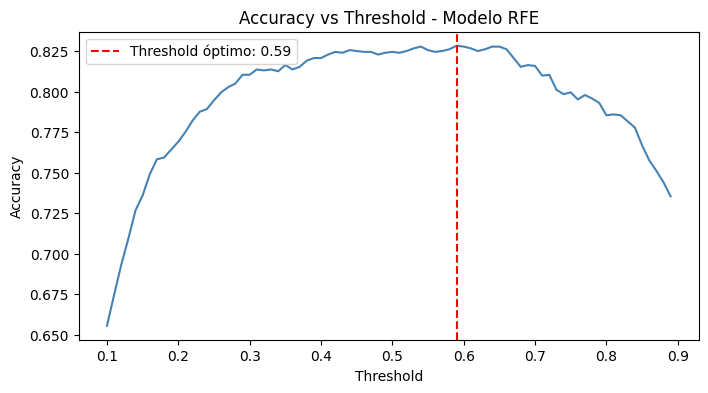

In [93]:
# Probabilidades del mejor modelo
y_proba_rfe = modelo_rfe.predict_proba(X_test)[:,1]

# Buscar threshold óptimo para Accuracy
thresholds = np.arange(0.1, 0.9, 0.01)
accuracies = []

for thresh in thresholds:
    y_pred_thresh = (y_proba_rfe >= thresh).astype(int)
    accuracies.append(accuracy_score(y_test, y_pred_thresh))

threshold_optimo_rfe = thresholds[np.argmax(accuracies)]
print(f"Threshold óptimo: {threshold_optimo_rfe:.2f}")
print(f"Accuracy máxima: {max(accuracies):.4f}")

# Gráfica
plt.figure(figsize=(8,4))
plt.plot(thresholds, accuracies, color='steelblue')
plt.axvline(threshold_optimo_rfe, color='red', linestyle='--',
            label=f'Threshold óptimo: {threshold_optimo_rfe:.2f}')
plt.xlabel('Threshold')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Threshold - Modelo RFE')
plt.legend()
plt.show()

=== EVALUACIÓN FINAL MODELO RFE ===
Threshold aplicado: 0.59

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       920
           1       0.84      0.81      0.83       920

    accuracy                           0.83      1840
   macro avg       0.83      0.83      0.83      1840
weighted avg       0.83      0.83      0.83      1840



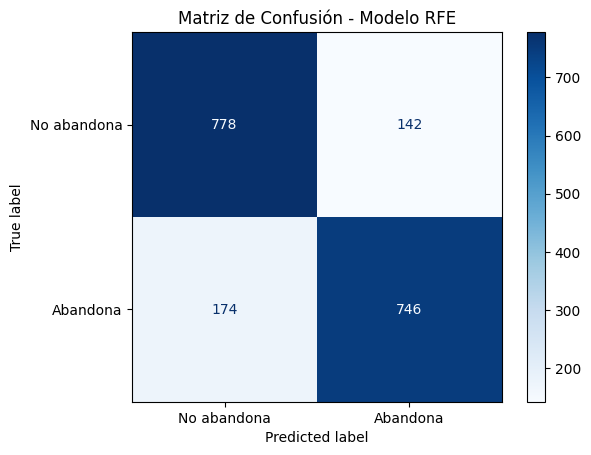

In [94]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred_rfe = (y_proba_rfe >= threshold_optimo_rfe).astype(int)

print("=== EVALUACIÓN FINAL MODELO RFE ===")
print(f"Threshold aplicado: {threshold_optimo_rfe:.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rfe))

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred_rfe)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                               display_labels=['No abandona','Abandona'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión - Modelo RFE')
plt.show()

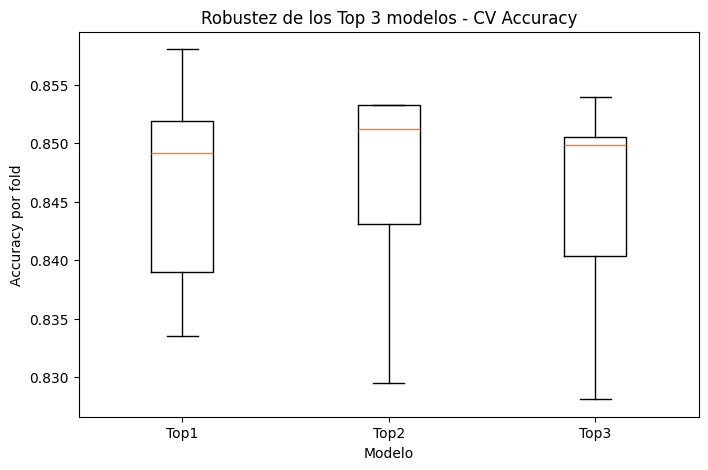

In [95]:
results = pd.DataFrame(modelo_rfe.cv_results_)

# Índice del mejor modelo
mejor_idx = modelo_rfe.best_index_

# Extraer accuracy por fold del mejor modelo
cols_splits = [f'split{i}_test_accuracy' for i in range(5)]
ac_mejor = results[cols_splits].iloc[mejor_idx]

# Si quieres comparar top 3 modelos
top3_idx = results['rank_test_accuracy'].nsmallest(3).index
ac_1 = results[cols_splits].iloc[top3_idx[0]]
ac_2 = results[cols_splits].iloc[top3_idx[1]]
ac_3 = results[cols_splits].iloc[top3_idx[2]]

plt.figure(figsize=(8,5))
plt.boxplot([ac_1.values, ac_2.values, ac_3.values],
            tick_labels=['Top1', 'Top2', 'Top3'])
plt.title('Robustez de los Top 3 modelos - CV Accuracy')
plt.xlabel('Modelo')
plt.ylabel('Accuracy por fold')
plt.show()

In [96]:
params_refinado = {
    'hidden_layer_sizes': [(25,), (30,), (35,), (40,), (50,)],
    'activation': ['tanh'],
    'solver': ['adam'],
    'alpha': [0.0005, 0.001, 0.002],
    'learning_rate': ['constant'],
    'learning_rate_init': [0.005, 0.01, 0.02],
    'max_iter': [1000]
}

modelo_rfe_v2 = RandomizedSearchCV(
    estimator=MLPClassifier(random_state=seed),
    param_distributions=params_refinado,
    n_iter=30,
    cv=5,
    scoring=scoring,
    refit='accuracy',
    random_state=seed,
    n_jobs=-1,
    verbose=1
)

modelo_rfe_v2.fit(X_train, y_train)

print("Mejores parámetros v2:", modelo_rfe_v2.best_params_)
print("Mejor Accuracy CV v2:", modelo_rfe_v2.best_score_.round(4))

# Comparar con modelo anterior
print(f"\nModelo v1 Accuracy CV: {modelo_rfe.best_score_:.4f}")
print(f"Modelo v2 Accuracy CV: {modelo_rfe_v2.best_score_:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Mejores parámetros v2: {'solver': 'adam', 'max_iter': 1000, 'learning_rate_init': 0.005, 'learning_rate': 'constant', 'hidden_layer_sizes': (50,), 'alpha': 0.0005, 'activation': 'tanh'}
Mejor Accuracy CV v2: 0.8467

Modelo v1 Accuracy CV: 0.8463
Modelo v2 Accuracy CV: 0.8467


Threshold óptimo: 0.59
Accuracy máxima: 0.8380


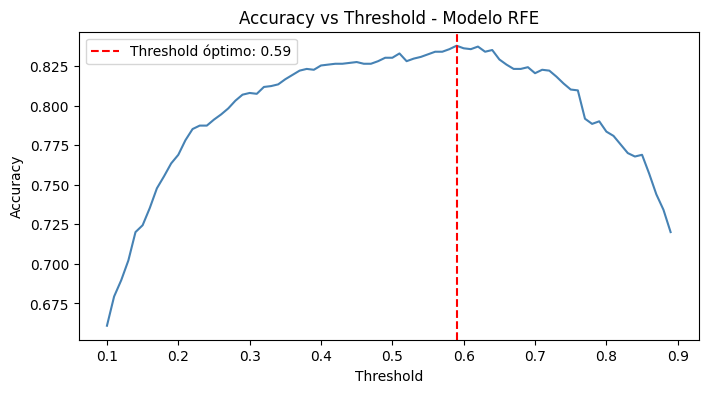

In [97]:
# Probabilidades del mejor modelo
y_proba_rfe = modelo_rfe_v2.predict_proba(X_test)[:,1]

# Buscar threshold óptimo para Accuracy
thresholds = np.arange(0.1, 0.9, 0.01)
accuracies = []

for thresh in thresholds:
    y_pred_thresh = (y_proba_rfe >= thresh).astype(int)
    accuracies.append(accuracy_score(y_test, y_pred_thresh))

threshold_optimo_rfe = thresholds[np.argmax(accuracies)]
print(f"Threshold óptimo: {threshold_optimo_rfe:.2f}")
print(f"Accuracy máxima: {max(accuracies):.4f}")

# Gráfica
plt.figure(figsize=(8,4))
plt.plot(thresholds, accuracies, color='steelblue')
plt.axvline(threshold_optimo_rfe, color='red', linestyle='--',
            label=f'Threshold óptimo: {threshold_optimo_rfe:.2f}')
plt.xlabel('Threshold')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Threshold - Modelo RFE')
plt.legend()
plt.show()

=== EVALUACIÓN FINAL MODELO RFE ===
Threshold aplicado: 0.59

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.86      0.84       920
           1       0.85      0.82      0.83       920

    accuracy                           0.84      1840
   macro avg       0.84      0.84      0.84      1840
weighted avg       0.84      0.84      0.84      1840



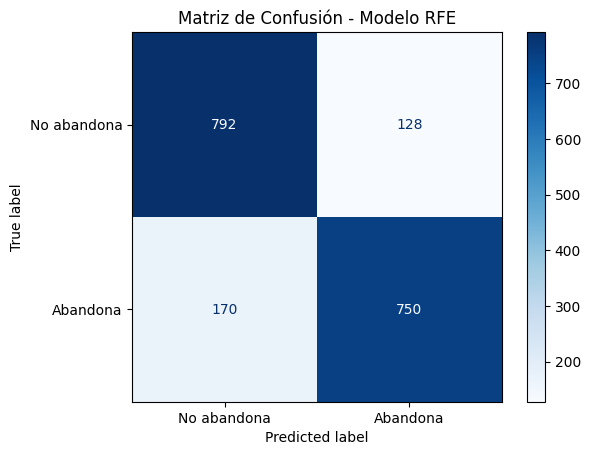

In [98]:
y_pred_rfe = (y_proba_rfeS >= threshold_optimo_rfe).astype(int)

print("=== EVALUACIÓN FINAL MODELO RFE ===")
print(f"Threshold aplicado: {threshold_optimo_rfe:.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rfe))

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred_rfe)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                               display_labels=['No abandona','Abandona'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión - Modelo RFE')
plt.show()

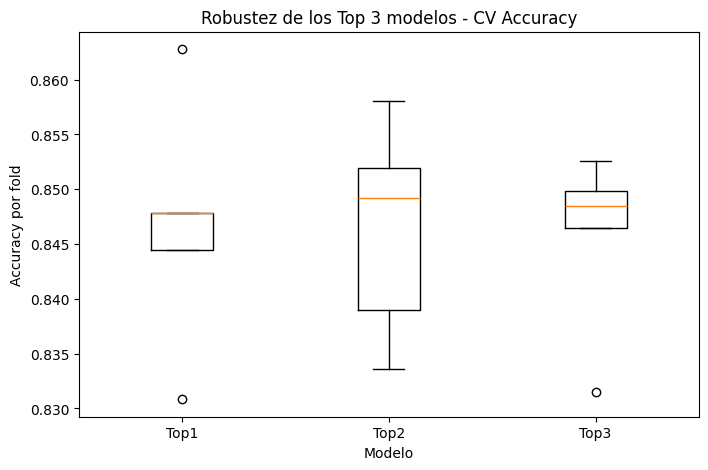

In [99]:
results_v2 = pd.DataFrame(modelo_rfe_v2.cv_results_)

# Índice del mejor modelo
mejor_idx = modelo_rfe_v2.best_index_

# Extraer accuracy por fold del mejor modelo
cols_splits = [f'split{i}_test_accuracy' for i in range(5)]
ac_mejor = results_v2[cols_splits].iloc[mejor_idx]

# Si quieres comparar top 3 modelos
top3_idx = results_v2['rank_test_accuracy'].nsmallest(3).index
ac_1 = results_v2[cols_splits].iloc[top3_idx[0]]
ac_2 = results_v2[cols_splits].iloc[top3_idx[1]]
ac_3 = results_v2[cols_splits].iloc[top3_idx[2]]

plt.figure(figsize=(8,5))
plt.boxplot([ac_1.values, ac_2.values, ac_3.values],
            tick_labels=['Top1', 'Top2', 'Top3'])
plt.title('Robustez de los Top 3 modelos - CV Accuracy')
plt.xlabel('Modelo')
plt.ylabel('Accuracy por fold')
plt.show()

# 3) Árbol de decisión y red neuronal basada en variables importantes

min_diurnas           0.391865
llamadas_atencion     0.202642
coste_nocturnas       0.178246
plan_internacional    0.138944
estado                0.088302
dtype: float64


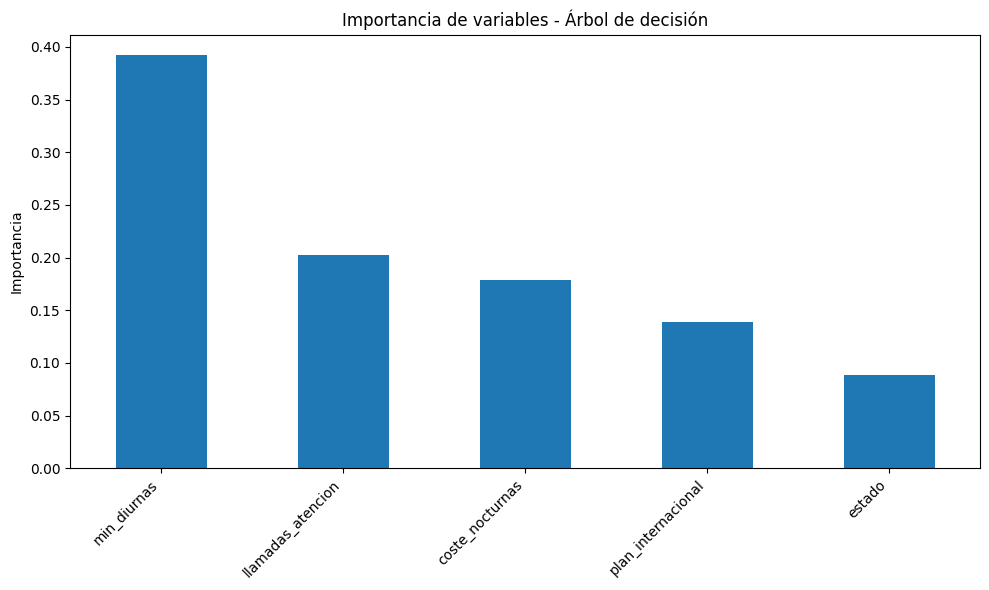

In [100]:
from sklearn.tree import DecisionTreeClassifier

arbol = DecisionTreeClassifier(random_state=seed)
arbol.fit(X_train, y_train)

# Importancia de variables
importancias = pd.Series(
    arbol.feature_importances_, 
    index=X_train.columns
).sort_values(ascending=False)

print(importancias)

# Gráfica
plt.figure(figsize=(10,6))
importancias.plot(kind='bar')
plt.title('Importancia de variables - Árbol de decisión')
plt.ylabel('Importancia')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

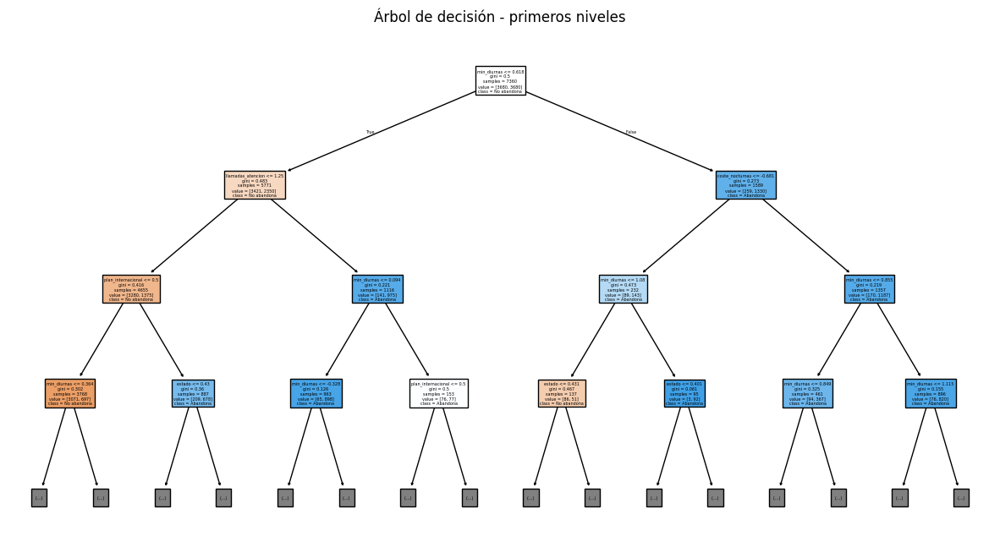

In [101]:
from sklearn.tree import plot_tree

plt.figure(figsize=(15,8))
plot_tree(arbol, 
          feature_names=X_train.columns.tolist(),
          class_names=['No abandona', 'Abandona'],
          filled=True,
          max_depth=3)  # Solo 3 niveles para que sea legible
plt.title('Árbol de decisión - primeros niveles')
plt.show()

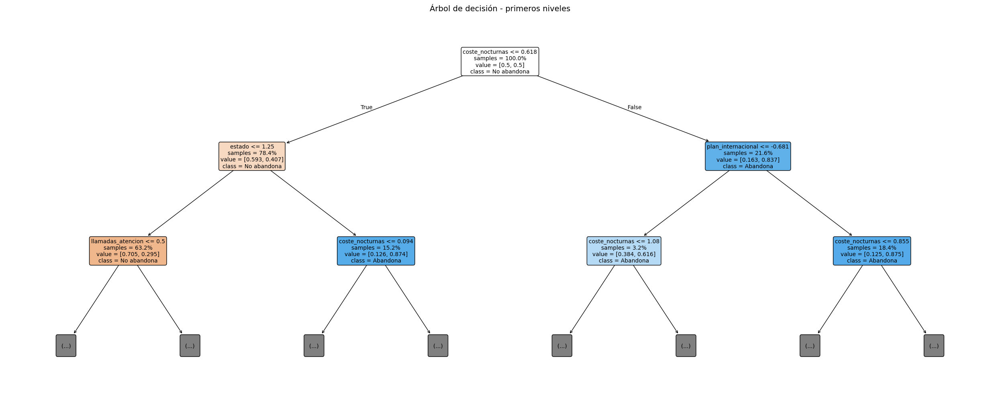

In [128]:
from sklearn.tree import plot_tree

plt.figure(figsize=(25, 10))
plot_tree(arbol,
          feature_names=X_train_arbol.columns.tolist(),
          class_names=['No abandona', 'Abandona'],
          filled=True,
          max_depth=2,  # Solo 2 niveles, más legible
          fontsize=10,
          rounded=True,
          impurity=False,  # Oculta gini para más limpieza
          proportion=True)
plt.title('Árbol de decisión - primeros niveles', fontsize=14)
plt.tight_layout()
plt.show()

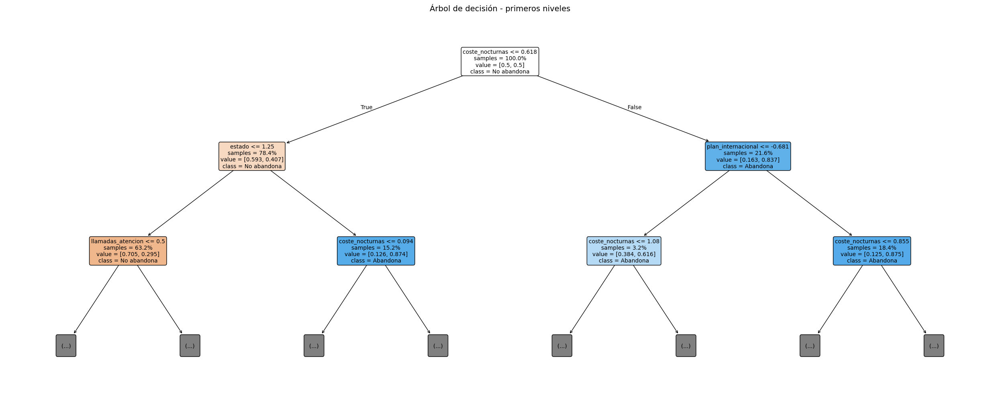

In [129]:
plt.figure(figsize=(25, 10))
plot_tree(arbol,
          feature_names=X_train_arbol.columns.tolist(),
          class_names=['No abandona', 'Abandona'],
          filled=True,
          max_depth=2,
          fontsize=10,
          rounded=True,
          impurity=False,
          proportion=True)
plt.title('Árbol de decisión - primeros niveles', fontsize=14)
plt.tight_layout()
plt.savefig('arbol_decision.png', dpi=150, bbox_inches='tight')
plt.show()

In [102]:
variables_arbol = importancias.index.tolist()

X_train_arbol = X_train[variables_arbol]
X_test_arbol = X_test[variables_arbol]

params_arbol = {
    'hidden_layer_sizes': [(25,), (30,), (35,), (40,), (50,)],
    'activation': ['tanh', 'relu', 'logistic'],
    'solver': ['adam', 'sgd'],
    'alpha': [0.00001, 0.0001, 0.001],
    'learning_rate': ['constant', 'adaptive'],
    'learning_rate_init': [0.001, 0.005, 0.01],
    'max_iter': [1000]
}

scoring = ['accuracy', 'recall_macro', 'f1_macro', 'precision_macro']

modelo_arbol = RandomizedSearchCV(
    estimator=MLPClassifier(random_state=seed),
    param_distributions=params_arbol,
    n_iter=50,
    cv=5,
    scoring=scoring,
    refit='recall_macro',
    random_state=seed,
    n_jobs=-1,
    verbose=1
)

modelo_arbol.fit(X_train_arbol, y_train)

print("Mejores parámetros:", modelo_arbol.best_params_)
print("Mejor Recall CV:", modelo_arbol.best_score_.round(4))

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Mejores parámetros: {'solver': 'adam', 'max_iter': 1000, 'learning_rate_init': 0.01, 'learning_rate': 'adaptive', 'hidden_layer_sizes': (50,), 'alpha': 1e-05, 'activation': 'logistic'}
Mejor Recall CV: 0.8488


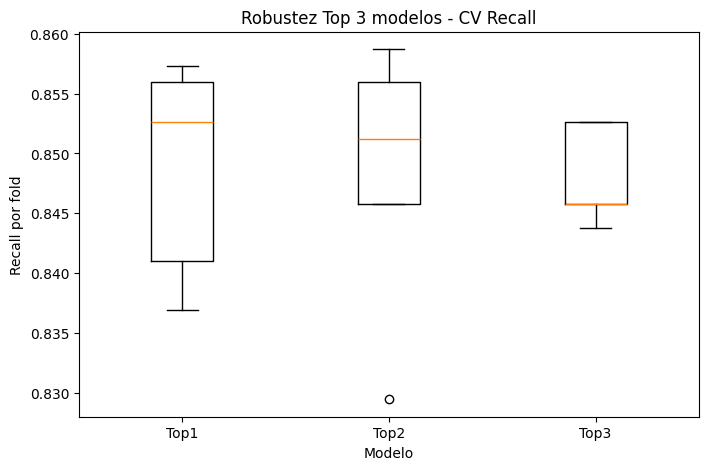

In [106]:
results_arbol = pd.DataFrame(modelo_arbol_v2.cv_results_)
mejor_idx_arbol = modelo_arbol_v2.best_index_

cols_splits = [f'split{i}_test_recall_macro' for i in range(5)]

top3_idx = results_arbol['rank_test_recall_macro'].nsmallest(3).index
ac_1 = results_arbol[cols_splits].iloc[top3_idx[0]]
ac_2 = results_arbol[cols_splits].iloc[top3_idx[1]]
ac_3 = results_arbol[cols_splits].iloc[top3_idx[2]]

plt.figure(figsize=(8,5))
plt.boxplot([ac_1.values, ac_2.values, ac_3.values],
            tick_labels=['Top1', 'Top2', 'Top3'])
plt.title('Robustez Top 3 modelos - CV Recall')
plt.xlabel('Modelo')
plt.ylabel('Recall por fold')
plt.show()

=== EVALUACIÓN FINAL MODELO ÁRBOL ===
Threshold aplicado: 0.10

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.49      0.65       920
           1       0.66      0.97      0.78       920

    accuracy                           0.73      1840
   macro avg       0.80      0.73      0.72      1840
weighted avg       0.80      0.73      0.72      1840



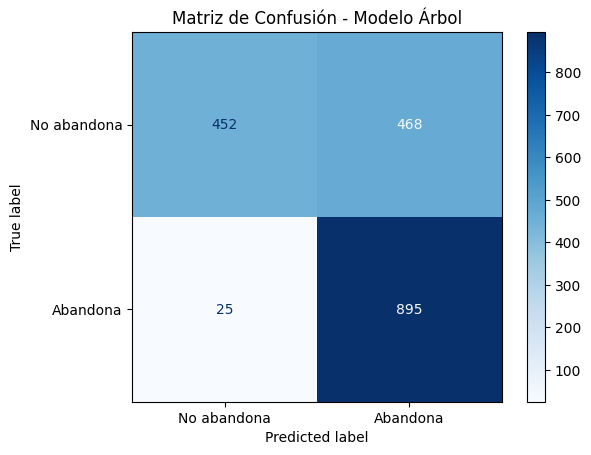

In [105]:
y_pred_arbol = (y_proba_arbol >= threshold_optimo_arbol).astype(int)

print("=== EVALUACIÓN FINAL MODELO ÁRBOL ===")
print(f"Threshold aplicado: {threshold_optimo_arbol:.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_arbol))

cm = confusion_matrix(y_test, y_pred_arbol)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['No abandona','Abandona'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión - Modelo Árbol')
plt.show()

In [103]:
params_arbol_v2 = {
    'hidden_layer_sizes': [(50,), (60,), (70,), (80,)],
    'activation': ['logistic'],
    'solver': ['adam'],
    'alpha': [0.000001, 0.000005, 0.00001],
    'learning_rate': ['adaptive'],
    'learning_rate_init': [0.005, 0.01, 0.02],
    'max_iter': [1000]
}

modelo_arbol_v2 = RandomizedSearchCV(
    estimator=MLPClassifier(random_state=seed),
    param_distributions=params_arbol_v2,
    n_iter=30,
    cv=5,
    scoring=scoring,
    refit='recall_macro',
    random_state=seed,
    n_jobs=-1,
    verbose=1
)

modelo_arbol_v2.fit(X_train_arbol, y_train)

print("Mejores parámetros v2:", modelo_arbol_v2.best_params_)
print("Mejor Recall CV v2:", modelo_arbol_v2.best_score_.round(4))
print(f"Modelo v1 Recall CV: {modelo_arbol.best_score_:.4f}")
print(f"Modelo v2 Recall CV: {modelo_arbol_v2.best_score_:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Mejores parámetros v2: {'solver': 'adam', 'max_iter': 1000, 'learning_rate_init': 0.02, 'learning_rate': 'adaptive', 'hidden_layer_sizes': (70,), 'alpha': 1e-05, 'activation': 'logistic'}
Mejor Recall CV v2: 0.8488
Modelo v1 Recall CV: 0.8488
Modelo v2 Recall CV: 0.8488


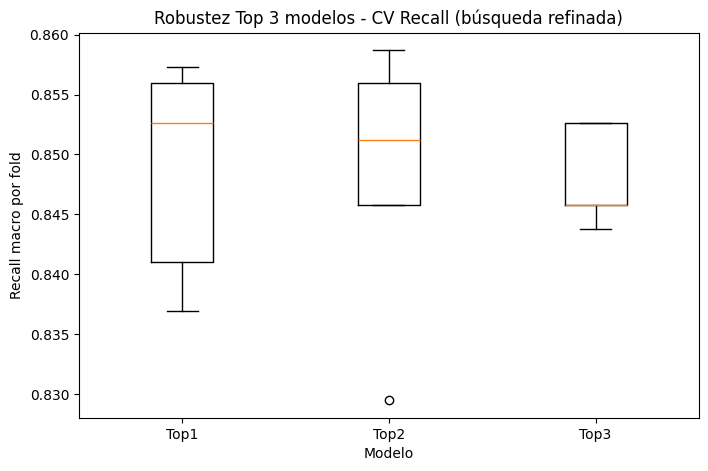

In [109]:
results_arbol_v2 = pd.DataFrame(modelo_arbol_v2.cv_results_)

cols_splits_recall = [f'split{i}_test_recall_macro' for i in range(5)]

top3_idx = results_arbol_v2['rank_test_recall_macro'].nsmallest(3).index
ac_1 = results_arbol_v2[cols_splits_recall].iloc[top3_idx[0]]
ac_2 = results_arbol_v2[cols_splits_recall].iloc[top3_idx[1]]
ac_3 = results_arbol_v2[cols_splits_recall].iloc[top3_idx[2]]

plt.figure(figsize=(8,5))
plt.boxplot([ac_1.values, ac_2.values, ac_3.values],
            tick_labels=['Top1', 'Top2', 'Top3'])
plt.title('Robustez Top 3 modelos - CV Recall (búsqueda refinada)')
plt.xlabel('Modelo')
plt.ylabel('Recall macro por fold')
plt.show()

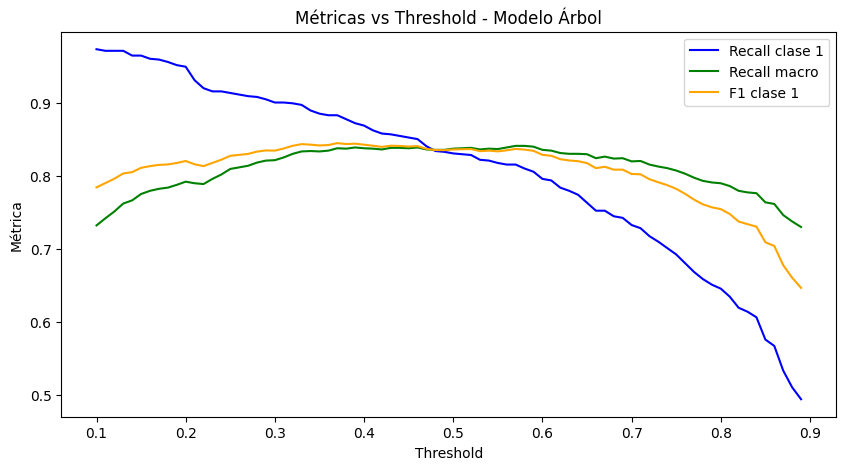

In [107]:
from sklearn.metrics import recall_score, f1_score

recalls_1 = []
recalls_macro = []
f1s = []

for thresh in thresholds:
    y_pred_thresh = (y_proba_arbol >= thresh).astype(int)
    recalls_1.append(recall_score(y_test, y_pred_thresh))
    recalls_macro.append(recall_score(y_test, y_pred_thresh, average='macro'))
    f1s.append(f1_score(y_test, y_pred_thresh))

# Graficar las tres curvas juntas
plt.figure(figsize=(10,5))
plt.plot(thresholds, recalls_1, label='Recall clase 1', color='blue')
plt.plot(thresholds, recalls_macro, label='Recall macro', color='green')
plt.plot(thresholds, f1s, label='F1 clase 1', color='orange')
plt.xlabel('Threshold')
plt.ylabel('Métrica')
plt.title('Métricas vs Threshold - Modelo Árbol')
plt.legend()
plt.show()

Threshold óptimo por F1: 0.37
Recall clase 1: 0.8826
Recall macro: 0.8375
F1 clase 1: 0.8445

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.79      0.83       920
           1       0.81      0.88      0.84       920

    accuracy                           0.84      1840
   macro avg       0.84      0.84      0.84      1840
weighted avg       0.84      0.84      0.84      1840



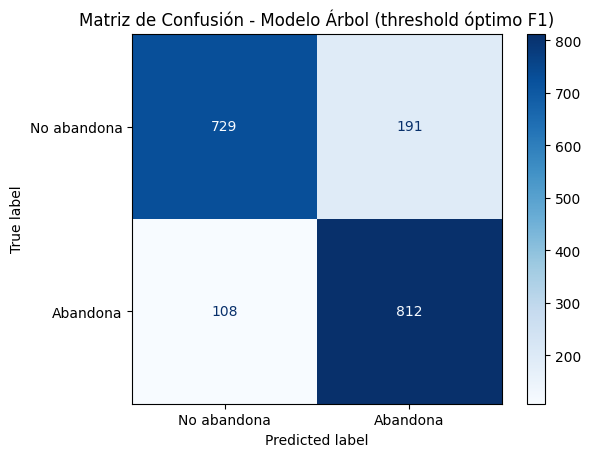

In [108]:
# Threshold óptimo por F1 como criterio de equilibrio
threshold_optimo_arbol = thresholds[np.argmax(f1s)]
print(f"Threshold óptimo por F1: {threshold_optimo_arbol:.2f}")

# Métricas en ese punto
y_pred_arbol = (y_proba_arbol >= threshold_optimo_arbol).astype(int)
print(f"Recall clase 1: {recall_score(y_test, y_pred_arbol):.4f}")
print(f"Recall macro: {recall_score(y_test, y_pred_arbol, average='macro'):.4f}")
print(f"F1 clase 1: {f1_score(y_test, y_pred_arbol):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_arbol))

cm = confusion_matrix(y_test, y_pred_arbol)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['No abandona','Abandona'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión - Modelo Árbol (threshold óptimo F1)')
plt.show()

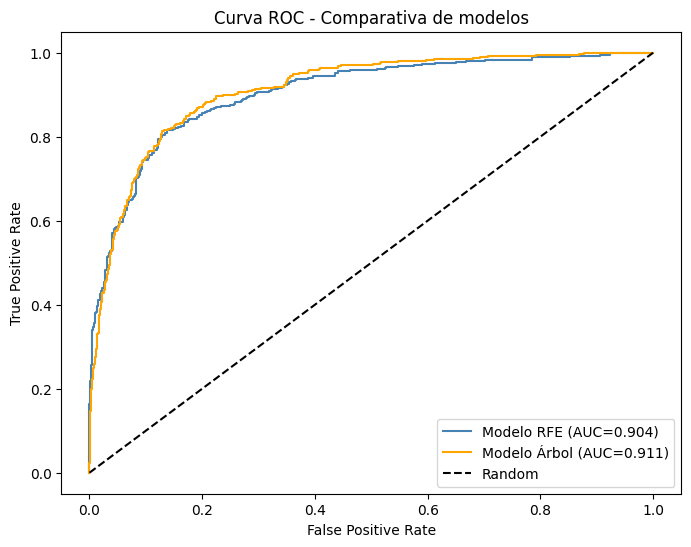

In [110]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr_rfe, tpr_rfe, _ = roc_curve(y_test, y_proba_rfe)
fpr_arbol, tpr_arbol, _ = roc_curve(y_test, y_proba_arbol)

auc_rfe = roc_auc_score(y_test, y_proba_rfe)
auc_arbol = roc_auc_score(y_test, y_proba_arbol)

plt.figure(figsize=(8,6))
plt.plot(fpr_rfe, tpr_rfe, label=f'Modelo RFE (AUC={auc_rfe:.3f})', color='steelblue')
plt.plot(fpr_arbol, tpr_arbol, label=f'Modelo Árbol (AUC={auc_arbol:.3f})', color='orange')
plt.plot([0,1],[0,1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC - Comparativa de modelos')
plt.legend()
plt.show()